# HW 4: Elastomeric Bridge Bearing Model Informed by FEM
**Name:** Xiangdong Yang  
**Date:** Sep 23, 2025

The code of this homework is written in python with jax.

## 1 Revise the Deformation Field

Observing the results produced by the FEM models, I decide to change the deformation function in the $y$ direction to be:
$$
v(x,y,z)=\frac{a}{2\sqrt{3}}\tan{(\frac{2\pi}{3H}y-\frac{\pi}{3})}+\frac{a}{2}
$$

In [1]:
import jax.numpy as jnp
import jax
from einops import rearrange
import matplotlib.pyplot as plt

In [2]:
H = 12.0 #in.
W = 27.0 #in.
nu = 0.499 #Poisson's ratio for natural rubber 

a = -0.5 #displacement at top of bearing, plane A-A-A-A
b = -nu * a #displacement at side of bearing, plane B-B-B-B
c = -nu * a #displacement at front of bearing, plane A-A-B-B

E=275.0 #psi, Young's modulus for natural rubber
G=E/(2*(1+nu)) #shear modulus

In [3]:
def u(point):
    return b*jnp.sin(jnp.pi*point[1]/H)*1/(W/2)*(point[0]-W/2)

def v(point):
    return a/(2*jnp.sqrt(3))*(jnp.tan(2*jnp.pi/(3*H)*point[1]-jnp.pi/3)+jnp.sqrt(3))

def w(point):
    return c*jnp.sin(jnp.pi*point[1]/H)*1/(W/2)*(point[2]-W/2)
@jax.jit
def get_deformation_field(point):
    return jnp.array([u(point), v(point), w(point)])

@jax.jit
def get_deformation_gradient(point):
    return jax.jacfwd(get_deformation_field)(point)

@jax.jit
def get_strain_field(point):
    grad=get_deformation_gradient(point)
    return 0.5 * (grad + grad.T)
nx=50
ny=50
nz=50

meshgrid = jnp.array(jnp.meshgrid(jnp.linspace(0, W, nx), jnp.linspace(0, H, ny), jnp.linspace(0, W, nz)))
meshgrid = rearrange(meshgrid, 'd x y z -> (x y z) d')
deformations = jax.vmap(get_deformation_field)(meshgrid)
deformed_shape = meshgrid + deformations

In [4]:
S=jnp.array(
    [[1/E,-nu/E,-nu/E,0,0,0],
    [-nu/E,1/E,-nu/E,0,0,0],
    [-nu/E,-nu/E,1/E,0,0,0],
    [0,0,0,1/G,0,0],
    [0,0,0,0,1/G,0],
    [0,0,0,0,0,1/G]]
)
C=jnp.linalg.inv(S)

In [5]:
@jax.jit
def get_stress_field(point):
    strain=get_strain_field(point)
    strain_vector=jnp.array([
        strain[0,0],
        strain[1,1],
        strain[2,2],
        2*strain[0,1],
        2*strain[0,2],
        2*strain[1,2]
    ])
    stress_vector = C@strain_vector
    stress_tensor=jnp.array([
        [stress_vector[0], stress_vector[3], stress_vector[4]],
        [stress_vector[3], stress_vector[1], stress_vector[5]],
        [stress_vector[4], stress_vector[5], stress_vector[2]]
    ])
    return stress_tensor

In [6]:
stress_tensor=jax.vmap(get_stress_field)(meshgrid)

## 2 Check Saint Venant's Compatibility
The compatibility condition can be checked using the same code from HW3. As shown below, compatability is observed.

In [7]:
def check_compatibility(point):
    second_deriv_strain=jax.jacfwd(jax.jacfwd(get_strain_field))(point)
    e_ijkl=second_deriv_strain
    e_klij=rearrange(second_deriv_strain,"i j k l->k l i j")
    e_ikjl=rearrange(second_deriv_strain,"i j k l->i k j l")
    e_jlik=rearrange(second_deriv_strain,"i j k l->k i l j")
    error=e_ijkl+e_klij-e_ikjl-e_jlik
    return error,jnp.all(error==0,axis=None)
error_field,compatibility=jax.vmap(check_compatibility)(meshgrid)
compatibility=jnp.all(compatibility)
print(f"Strain Compatibility is {compatibility}")

Strain Compatibility is True


## 3 Check Volume of Deformed Bearing
Original volume of the bearing is:
$$
V=W^2H=8748
$$
Volume of the deformed bearing can be obtained analytically with the following :
$$
V'=\int_{0}^{H'}[W+2asin(\frac{\pi y}{H'})]^2dy
$$
where $H'$ and $V'$ are the height and volume of the deformed bearing.
Doing the integration yields:
$$
V'=(2a+W^2+\frac{8aW}{\pi})H'
$$
Plugging in $H'=11.5, a=0.25$ yields:
$$
V'=7976.66
$$
This check is important because the unit volume contraction from pressure is inversely proportional to the  modulus of volumetric expansion $K=\frac{E}{3(1-2\nu)}$. For rubber whose poisson ratio $\nu\approx0.5$, $K\rightarrow\infty$, which indicates that no volumetric contraction should happen. Here however, $\nu$ is assumed to take a value slightly smaller than $0.5$ to avoid dealing with infinity in the program. A small amount of volumetric contraction should therefore be expected.

## 4 Comparison with Abaqus Model
The stress contours for the modified deformed bearing model are shown below.

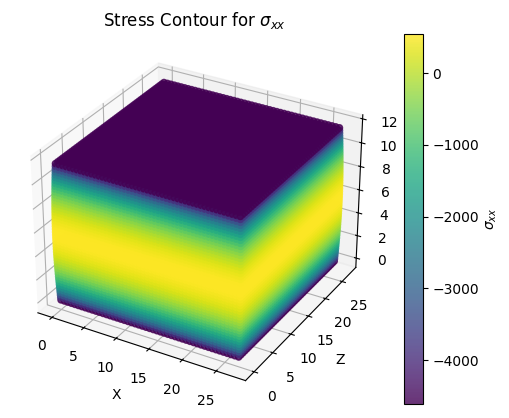

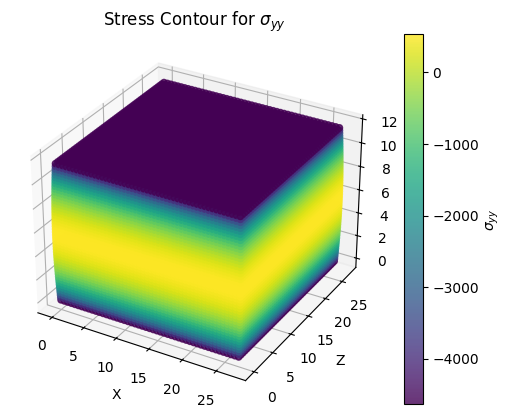

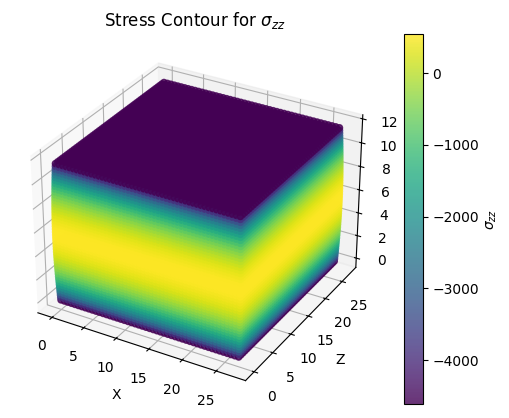

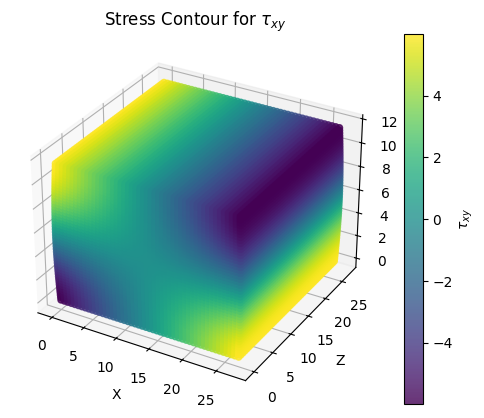

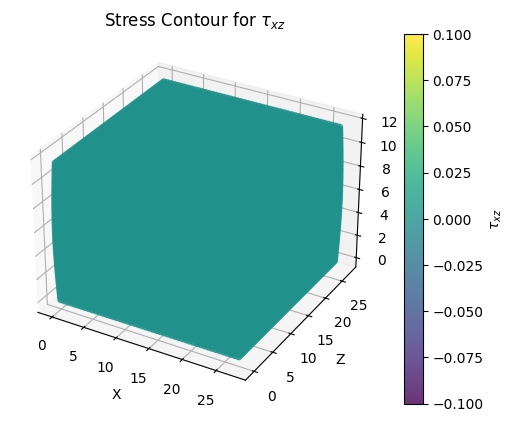

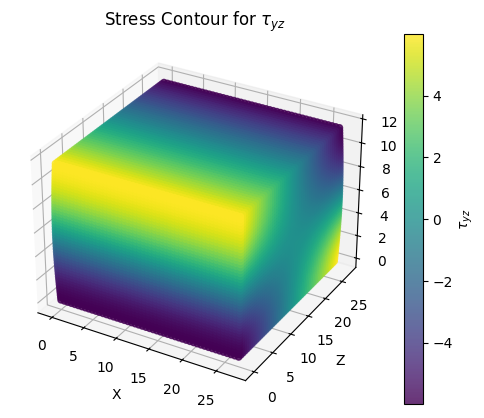

In [8]:
stress_components = [
    (0,0,r'$\sigma_{xx}$'),
    (1,1,r'$\sigma_{yy}$'),
    (2,2,r'$\sigma_{zz}$'),
    (0,1,r'$\tau_{xy}$'),
    (0,2,r'$\tau_{xz}$'),
    (1,2,r'$\tau_{yz}$')
]

for i,j,label in stress_components:
    plt.figure()
    
    ax = plt.axes(projection='3d')


    sc = ax.scatter(deformed_shape[:, 0],
                    deformed_shape[:, 2],
                    deformed_shape[:, 1],
                    c=stress_tensor[:, i,j], cmap='viridis', alpha=0.8)

    plt.colorbar(sc, label=label)

    ax.set_xlabel('X')
    ax.set_ylabel('Z')
    ax.set_zlabel('Y')
    ax.set_title(f'Stress Contour for {label}')

    plt.show()
